## MTL Trajet: 15 Single-user Routine, Mode, and Speed Context (Flag 15)

### Dataset Overview
One user's work and discretionary trajectories with purpose, transport mode, distance, recurring route geometry, and timestamped point speeds labelled by center, transition, or suburban spatial context.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Analyze individual mobility patterns across activity purposes and spatial contexts.

Role: Individual mobility-pattern analyst


Category: Single-user routine regularity, discretionary mode flexibility, distance-mode structure, and center-suburban speed context

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How do work-trip departure times and spatial endpoints compare with the user's discretionary trips?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

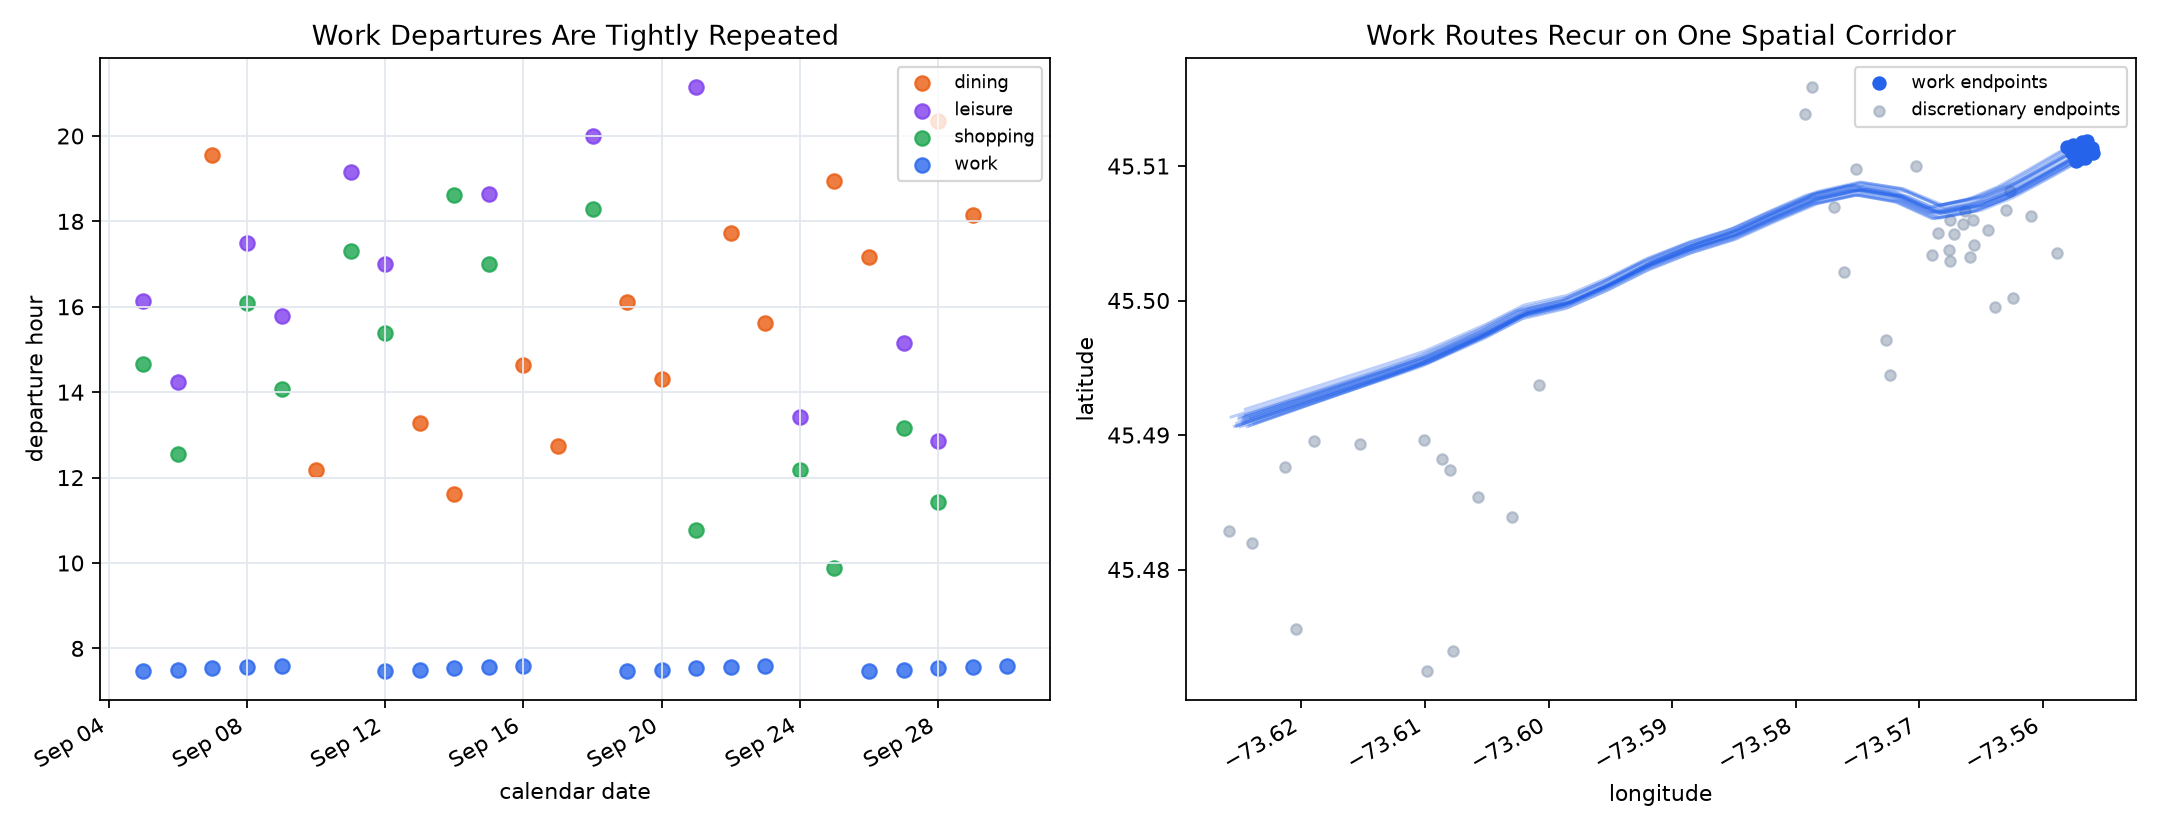

In [ ]:
df.groupby('purpose_group').agg(start_hour_std=('start_hour','std'), end_lon_std=('end_lon','std'), end_lat_std=('end_lat','std'))
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/work_time_and_spatial_regularity.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "work_time_spatial_regularity",
  "insight": "Work-related trips exhibit highly regular departure times and recurrent spatial patterns, forming the most stable component of the user's mobility routine.",
  "insight_type": "overall_pattern",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Work Departure and Spatial Regularity",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/work_time_and_spatial_regularity.png"
  },
  "question": "How do work-trip departure times and spatial endpoints compare with the user's discretionary trips?",
  "code": "df.groupby('purpose_group').agg(start_hour_std=('start_hour','std'), end_lon_std=('end_lon','std'), end_lat_std=('end_lat','std'))",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "trajectory_timestamp",
    "trajectory_id",
    "gps_position"
  ]
}

### **Question 2**: How many transport modes are represented for work versus each discretionary purpose?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

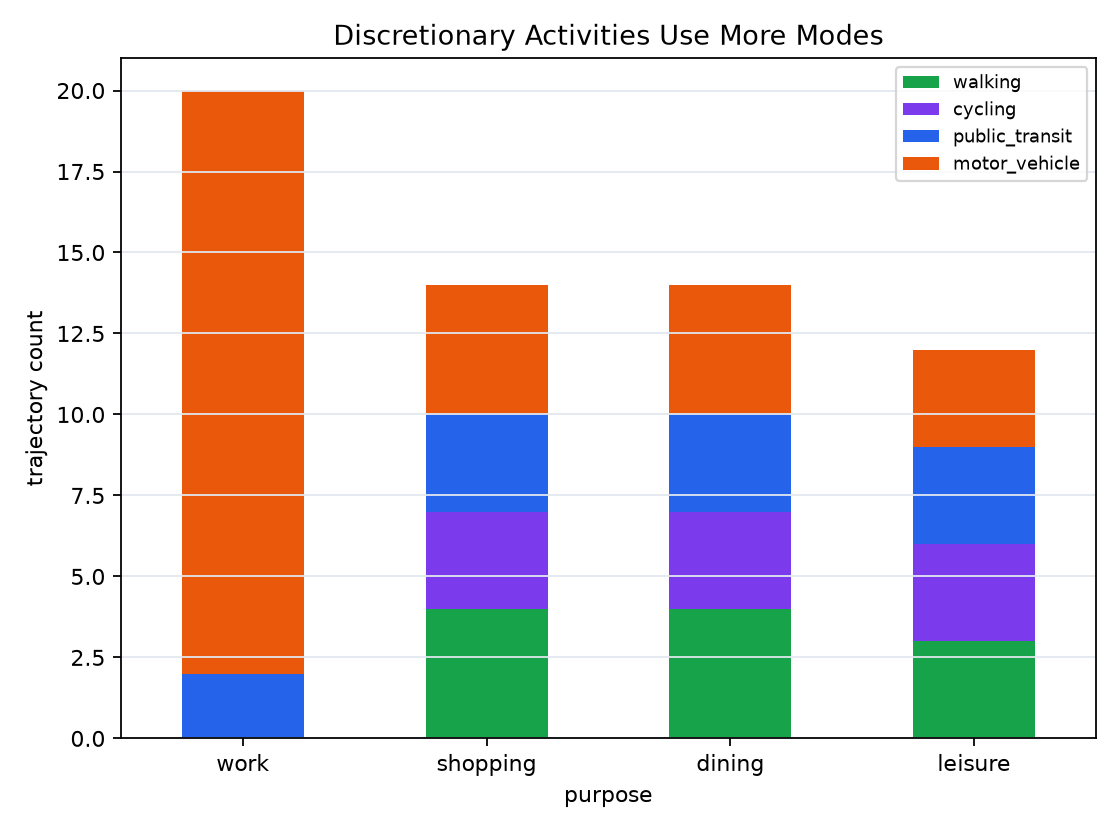

In [ ]:
df.groupby('purpose_group').mode_group.nunique()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/purpose_mode_flexibility.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "purpose_mode_flexibility",
  "insight": "The user shows substantially greater mode flexibility for shopping, dining, and leisure trips than for recurrent work trips.",
  "insight_type": "group_comparison",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Mode Flexibility by Purpose",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/purpose_mode_flexibility.png"
  },
  "question": "How many transport modes are represented for work versus each discretionary purpose?",
  "code": "df.groupby('purpose_group').mode_group.nunique()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "transport_mode",
    "trajectory_id"
  ]
}

### **Question 3**: How do the available transport modes change from short to intermediate and longer discretionary trips?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

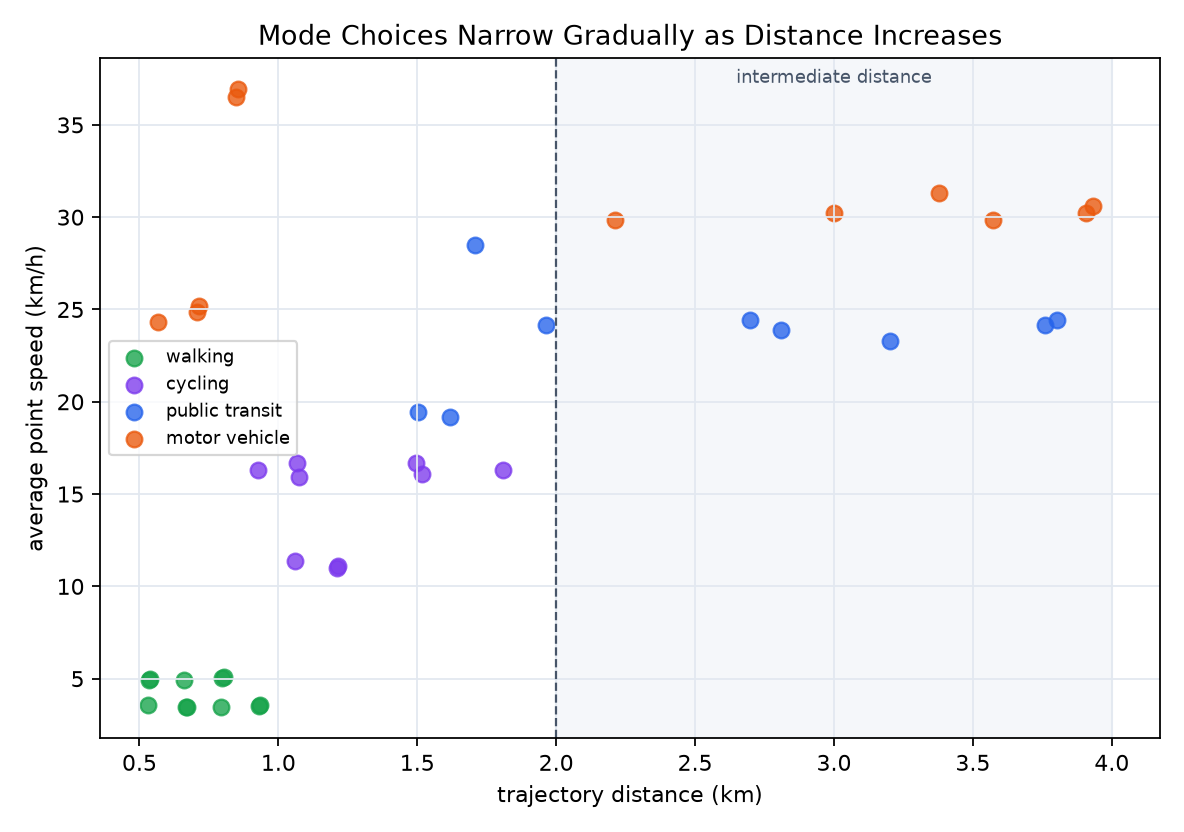

In [ ]:
pd.crosstab(pd.cut(df[df.purpose_group.ne('work')].distance_km, [-float('inf'),2,4,float('inf')], labels=['short','intermediate','long']), df[df.purpose_group.ne('work')].mode_group)
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/discretionary_distance_mode_structure.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "discretionary_distance_mode_structure",
  "insight": "Short discretionary trips involve multiple transport modes, whereas longer trips converge toward the smaller set of motor-vehicle and public-transit modes.",
  "insight_type": "distribution_comparison",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Discretionary Distance and Mode Structure",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/discretionary_distance_mode_structure.png"
  },
  "question": "How do the available transport modes change from short to intermediate and longer discretionary trips?",
  "code": "pd.crosstab(pd.cut(df[df.purpose_group.ne('work')].distance_km, [-float('inf'),2,4,float('inf')], labels=['short','intermediate','long']), df[df.purpose_group.ne('work')].mode_group)",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "transport_mode",
    "gps_position",
    "trajectory_id",
    "point_speed"
  ]
}

### **Question 4**: For each transport mode, how do point speeds differ between center and suburban areas?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

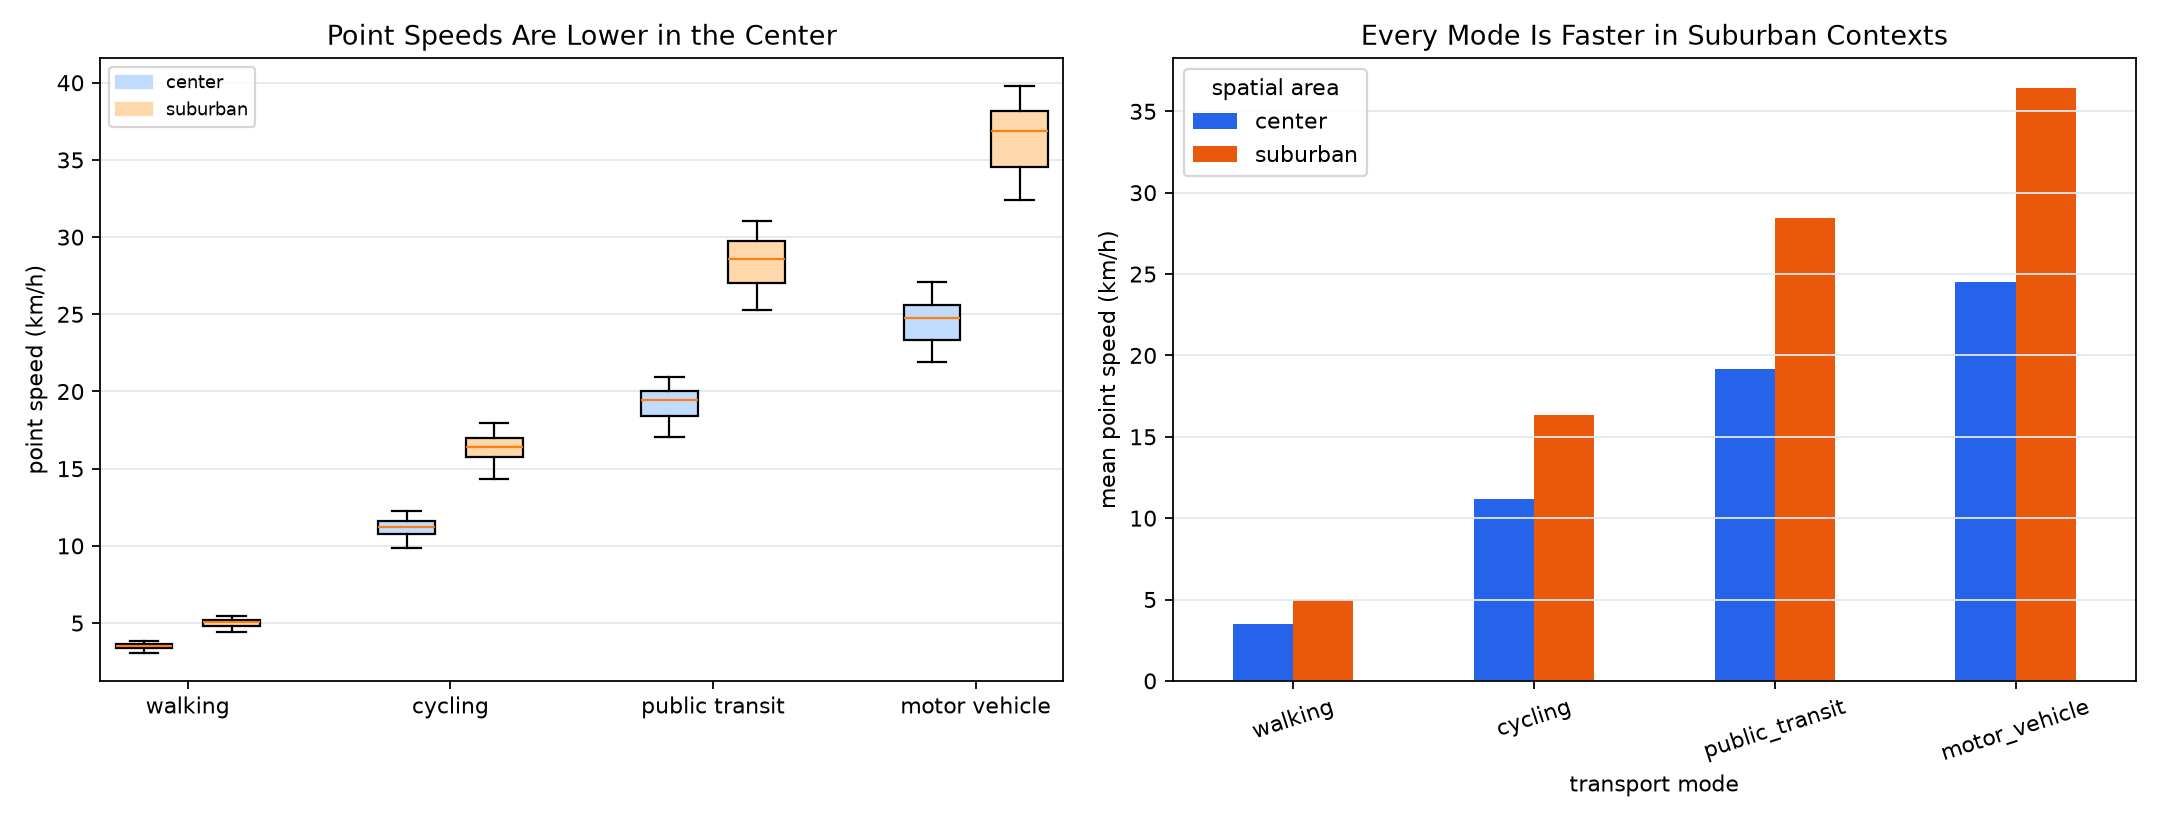

In [ ]:
points[points.spatial_area.isin(['center','suburban'])].groupby(['mode_group','spatial_area']).speed_kmh.agg(['count','mean','std'])
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/point_speed_by_center_suburban_context.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "mode_speed_spatial_context",
  "insight": "The user's point speeds are lower in the center area and higher in suburban areas for every transportation mode.",
  "insight_type": "group_comparison",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Point Speed by Center and Suburban Context",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/point_speed_by_center_suburban_context.png"
  },
  "question": "For each transport mode, how do point speeds differ between center and suburban areas?",
  "code": "points[points.spatial_area.isin(['center','suburban'])].groupby(['mode_group','spatial_area']).speed_kmh.agg(['count','mean','std'])",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "transport_mode",
    "gps_position",
    "point_speed"
  ]
}

### Summary of Findings (Flag 15)

This user's work travel is the most temporally and spatially regular activity. Shopping, dining, and leisure use a broader range of modes; short discretionary trips are multimodal, whereas longer ones use motor vehicle or public transit. Point speeds are consistently lower in center contexts across modes.